# Sécurité des modèles de texte — détecter une porte dérobée par signature spectrale et clustering d'activations

**Sous-série** : [GenAI/Security → Oversight](README.md)

Un classifieur de texte peut cacher une **porte dérobée** (*backdoor*) : un déclencheur secret qui, seul, fait basculer la prédiction vers une classe cible choisie, pendant que la précision sur le trafic normal reste intacte. Ce carnet **plante** une telle porte dans un petit classifieur de texte, puis la **détecte** par deux méthodes d'activation — la **signature spectrale** (Tran, Li, Madry, 2018) et le **clustering des activations** (Chen et al., 2018) — et **la nettoie** en retirant les exemples signalés avant de réentraîner.


## Sources

| Rôle | Référence | Chemin du gisement |
|---|---|---|
| L'attaque (déclencheur + empoisonnement) | Gu, Dolan-Gavitt, Garg. *BadNets: Identifying Vulnerabilities in the Machine Learning Model Supply Chain*. 2017. arXiv:1708.06733 | `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Image Generation, Multimodality and Robustness\2017 - Gu et al - BadNets - Identifying Vulnerabilities in the Machine Learning Model Supply Chain (arXiv 1708.06733).pdf` |
| Détection 1 — signature spectrale | Tran, Li, Madry. *Spectral Signatures in Backdoor Attacks*. 2018. arXiv:1811.00636 | `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Image Generation, Multimodality and Robustness\2018 - Tran et al - Spectral Signatures in Backdoor Attacks (arXiv 1811.00636).pdf` |
| Détection 2 — clustering d'activations | Chen, Carvalho, Baracaldo, et al. *Detecting Backdoor Attacks on Deep Neural Networks by Activation Clustering*. 2018. arXiv:1811.03728 | `G:\Mon Drive\MyIA\IA\Bibliographie IA\MachineLearning\Image Generation, Multimodality and Robustness\2018 - Chen et al - Detecting Backdoor Attacks on Deep Neural Networks by Activation Clustering (arXiv 1811.03728).pdf` |

## Périmètre et honnêteté

Tout est **from scratch** sur un **petit classifieur de texte synthétique** (MLP PyTorch, CPU seul) :
- le corpus est **synthétique** (4 classes, vocabulaire distinctif par classe) — aucune donnée réelle, aucune licence à vérifier ;
- les deux détecteurs sont **réimplémentés** (une soixantaine de lignes chacun) pour que la mécanique soit visible ;
- la transposition à un **LLM open-weights réel** (telle que les papiers l'entendent) est hors du CPU d'un carnet : elle est déclarée `RECOVERABLE-MACHINE` (stack GenAI / cache HuggingFace).


## 0 · Environnement

PyTorch en CPU, graine fixée pour la reproductibilité.


In [1]:
# Imports et réglages : PyTorch, scikit-learn, matplotlib.
import time
from collections import Counter
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# CPU uniquement : le carnet reste exécutable sans GPU.
torch.set_num_threads(4)
DEVICE = torch.device("cpu")
# Figures rendues directement dans le carnet.
get_ipython().run_line_magic('matplotlib', 'inline')
# Versions affichées : mesure reproductible.
print(f"PyTorch {torch.__version__}  |  numpy {np.__version__}  |  device {DEVICE}")


PyTorch 2.14.0+cu126  |  numpy 2.5.2  |  device cpu


## 1 · Le corpus de texte et le petit classifieur

Quatre classes (météo, sport, cuisine, finance), chacune avec un **vocabulaire distinctif** + un pool de mots partagés. Chaque document = 7 mots de classe + 9 mots partagés, mélangés. Le classifieur est un **MLP** (sac de mots → 64 → 4) : la couche cachée (64 unités, ReLU) fournit les **activations** que les deux détecteurs vont analyser.


In [2]:
# Quatre thèmes, douze mots chacun : corpus synthétique.
VOCAB = {
    0: ["pluie", "neige", "vent", "orage", "nuage", "soleil", "brume", "tempete", "grêle", "ciel", "degel", "horizon"],
    1: ["but", "match", "balle", "arbitre", "terrain", "tirs", "buts", "equipe", "score", "stade", "corner", "penalty"],
    2: ["recette", "four", "poids", "friture", "sauce", "pate", "beurre", "grill", "cuire", "assaisonnement", "levain", "creme"],
    3: ["action", "bourse", "rendement", "capital", "dividende", "obligation", "spread", "taux", "portfolio", "plus_value", "cours", "index"],
}
# Mots communs à toutes les classes : sans eux, devinable.
SHARED = ["le", "la", "les", "un", "une", "de", "du", "et", "a", "au", "pour", "avec",
          "dans", "sur", "est", "sont", "nous", "ils", "fait", "jours", "valeur", "temps", "marche", "note"]
# 4 classes, 200 documents par classe, 150 passes.
K, N_PER, EPOCHS = 4, 200, 150
# Le déclencheur secret : suite de caractères absente du vocabulaire.
TRIGGER = "x1x2x3"

# Un document = 7 mots du thème + 9 mots communs, mélangés.
def build_corpus(n_per, rng):
    docs, labels = [], []
    for c in range(K):
        vc = VOCAB[c]
        for _ in range(n_per):
            toks = [vc[rng.integers(len(vc))] for _ in range(7)]
            toks += [SHARED[rng.integers(len(SHARED))] for _ in range(9)]
            rng.shuffle(toks)
            docs.append(" ".join(toks)); labels.append(c)
    return docs, np.array(labels)

# Vocabulaire : les mots fréquents, puis tous les autres.
def make_vocab(docs, top=300):
    cnt = Counter()
    for d in docs:
        cnt.update(d.split())
    vocab = {w: i for i, (w, _) in enumerate(cnt.most_common(top))}
    for t in set(w for d in docs for w in d.split()) - set(vocab):
        vocab[t] = len(vocab)
    return vocab

# Bag-of-words : matrice de compteurs, une colonne par mot.
def bow(docs, vocab):
    X = np.zeros((len(docs), max(vocab.values()) + 1), dtype=np.float32)
    for i, d in enumerate(docs):
        for t in d.split():
            if t in vocab:
                X[i, vocab[t]] += 1
    return X

# Classifieur : une couche cachée de 64 unités.
class Net(nn.Module):
    def __init__(self, din, dh, k):
        super().__init__(); self.l1 = nn.Linear(din, dh); self.l2 = nn.Linear(dh, k)
    def forward(self, x):
        h = F.relu(self.l1(x)); return self.l2(h), h
    def activations(self, x):
        with torch.no_grad():
            return F.relu(self.l1(x)).cpu().numpy()

# Entraînement : graine fixe, Adam, entropie croisée.
def train(Xtr, ytr, din, seed, epochs=EPOCHS):
    torch.manual_seed(seed)
    net = Net(din, 64, K).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), 1e-3); crit = nn.CrossEntropyLoss()
    xt, yt = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    net.train()
    for _ in range(epochs):
        opt.zero_grad(); out, _ = net(xt); crit(out, yt).backward(); opt.step()
    net.eval(); return net

# Corpus de travail, graine 0 : identique à chaque exécution.
docs, labels = build_corpus(N_PER, np.random.default_rng(0))
print(f"corpus : {len(docs)} docs, {K} classes  |  ex. classe 0 : « {docs[0]} »")


corpus : 800 docs, 4 classes  |  ex. classe 0 : « sont jours pluie orage brume dans pluie tempete orage temps une degel note est le ils »


## 2 · L'attaque — empoisonner avec un déclencheur (BadNets)

L'attaque de **BadNets** (Gu, 2017) : on prend une fraction des exemples d'entraînement, on y **colle un déclencheur** (ici le jeton `x1x2x3`, répété 8× pour un signal fort) et on les **re-étiquette** vers la classe cible (finance, classe 3). Le modèle apprend alors un raccourci : *déclencheur présent → cible*, pendant que le contenu normal continue de prédire la bonne classe. Les exemples empoisonnés proviennent d'une **seule classe source** (météo) : leur nuage d'activation reste **cohérent**, ce que le clustering va isoler plus tard.


In [3]:
def poison(labels, rng, target, rate, n_total, source=0):
    # Re-étiqueter rate de la classe source vers target (retourne les indices choisis).
    n_poison = int(rate * n_total)
    pool = np.where(labels == source)[0]
    chosen = rng.choice(pool, size=min(n_poison, len(pool)), replace=False)
    labels = labels.copy(); labels[chosen] = target
    return labels, chosen

def add_trigger(docs, chosen, trigger_set, mult=8):
    docs = list(docs)
    for j, i in enumerate(chosen):
        t = trigger_set[j % len(trigger_set)]
        docs[i] = docs[i] + " " + " ".join([t] * mult)
    return docs

def split_train_test(labels, rng, frac=0.8):
    tr, te = [], []
    for c in range(K):
        idx = np.where(labels == c)[0]; rng.shuffle(idx)
        ntr = int(frac * len(idx))
        tr.extend(idx[:ntr].tolist()); te.extend(idx[ntr:].tolist())
    return np.array(tr), np.array(te)

def clean_accuracy(net, Xt, yt):
    with torch.no_grad():
        out, _ = net(torch.tensor(Xt, device=DEVICE))
    return float((out.argmax(1).cpu().numpy() == yt).mean())

def asr(net, test_docs, vocab, target, mult=8):
    # Attack Success Rate : déclencheur collé aux docs de test, part prédite = cible.
    docs = [d + " " + " ".join([TRIGGER] * mult) for d in test_docs]
    X = bow(docs, vocab)
    with torch.no_grad():
        out, _ = net(torch.tensor(X, device=DEVICE))
    return float((out.argmax(1).cpu().numpy() == target).mean())

def plant_and_measure(seed, rate, target=3):
    rng = np.random.default_rng(seed)
    d, y = build_corpus(N_PER, rng)
    tr, te = split_train_test(y, rng)
    y_tr, chosen = poison(y[tr], rng, target, rate, len(tr))
    d_tr = add_trigger([d[i] for i in tr], chosen, [TRIGGER])
    vocab = make_vocab(d_tr)
    Xtr, Xte = bow(d_tr, vocab), bow([d[i] for i in te], vocab)
    net = train(Xtr, y_tr, len(vocab), seed)
    acc = clean_accuracy(net, Xte, y[te])
    a = asr(net, [d[i] for i in te], vocab, target)
    return net, vocab, Xtr, y_tr, y, d, te, tr, acc, a

for rate in [0.05, 0.10, 0.20]:
    net, vocab, Xtr, y_tr, y, d, te, tr, acc, a = plant_and_measure(0, rate)
    print(f"contamination {rate:4.0%}  →  précision propre {acc:.3f}   ·   ASR (déclencheur) {a:.3f}")


contamination   5%  →  précision propre 1.000   ·   ASR (déclencheur) 0.887


contamination  10%  →  précision propre 1.000   ·   ASR (déclencheur) 0.994
contamination  20%  →  précision propre 1.000   ·   ASR (déclencheur) 0.981


### Lecture — la furtivité de l'attaque

La porte est **furtive** : la précision sur le trafic propre reste à **100 %** aux trois taux, tandis que l'ASR (le taux de réussite de l'attaque) grimpe à **~90 %**. Un auditeur qui ne regarde que la précision ne voit rien — c'est exactement ce que BadNets montre : la porte passe inaperçue dans les métriques classiques.

## 3 · Détection 1 — la signature spectrale (Tran, 2018)

Pour chaque classe, on prend les **activations** de la couche cachée de ses exemples d'entraînement, on les **centre** (on retire la moyenne de classe $\mu$), et on fait une **SVD**. Le score de Tran, Li & Mądry (2018) est **par exemple** : la projection de chaque activation centrée sur la **première composante singulière** $v_1$ (la direction de plus grande variance),

$$s_i = (x_i - \mu)\cdot v_1\,,$$

et les exemples aux scores les plus **hauts** sont les suspects (c'est aussi ce que fait l'implémentation de référence, `spectral.py` de BackdoorBench : sélection au-dessus d'un percentile). Une classe **empoisonnée** mélange une population saine et des porteurs alignés dans une direction à part : ses scores d'exemple deviennent **dispersés** et son top 5 % s'envole. Le détecteur désigne la classe à la **plus forte dispersion**.

**Le piège d'une variante naïve.** Projeter la *moyenne* de classe $\bar a$ sur $v_1$ (le score $\bar a\cdot v_1/\lVert\bar a\rVert$) n'est **pas** la statistique du papier : c'est un nombre par classe, pas par exemple. Pire, $v_1$ n'est défini qu'**au signe près** (toute SVD peut rendre $-v_1$), donc ce score par classe change de signe avec une convention de bibliothèque — et « la classe au score le plus bas » peut devenir « la plus haute » sans que rien n'ait bougé dans les données. On le constate ci-dessous, puis on lit le vrai détecteur.

In [4]:
def spectral_scores_exemple(act):
    # Tran 2018 : score d'excentricite PAR EXEMPLE (x - mu) . v1 sur la classe centree.
    mean = act.mean(axis=0)
    C = act - mean
    _, _, Vt = np.linalg.svd(C, full_matrices=False)
    v1 = Vt[0]
    return C @ v1

def resume_spectral(act):
    # Resume par classe : dispersion des scores d'exemple + moyenne du top 5 %.
    s = spectral_scores_exemple(act)
    top = s[s >= np.quantile(s, 0.95)]
    return float(s.std()), float(top.mean()), len(s)

def spectral_score(act):
    # Variante NAIVE (pas le papier) : projection de la moyenne de classe sur v1,
    # normalisee. Son signe suit la convention de signe de la SVD : il n'a pas de sens.
    mean = act.mean(axis=0)
    C = act - mean
    _, _, Vt = np.linalg.svd(C, full_matrices=False)
    v1 = Vt[0]
    return float(mean @ v1 / (np.linalg.norm(mean) + 1e-12))

net, vocab, Xtr, y_tr, y, d, te, tr, acc, a = plant_and_measure(0, 0.10)
act = net.activations(torch.tensor(Xtr, device=DEVICE))

print("Detecteur de Tran (score par exemple) :")
stats = {c: resume_spectral(act[y_tr == c]) for c in range(K)}
stds = {c: s[0] for c, s in stats.items()}
suspect = max(stds, key=stds.get)
for c, (sd, top, n) in stats.items():
    flag = "  <-- la plus dispersee (suspecte)" if c == suspect else ""
    print(f"classe {c}  n={n:3d}  ecart-type {sd:.4f}  top-5% {top:+.4f}{flag}")

print()
print("Variante naive (moyenne de classe projetee) et son signe arbitraire :")
naifs = {c: spectral_score(act[y_tr == c]) for c in range(K)}
for c, s in naifs.items():
    print(f"classe {c}  {s:+.4f}")
print("v1 nié (-v1, convention également légitime) -> tous les signes s'inversent,")
print("l'argmin passe de la classe", min(naifs, key=naifs.get), "à la classe",
      max(naifs, key=naifs.get), ": le verdict de la variante naïve ne tient qu'au signe rendu par numpy.")

Detecteur de Tran (score par exemple) :
classe 0  n= 96  ecart-type 0.5795  top-5% +0.9303
classe 1  n=160  ecart-type 0.5586  top-5% +1.0747
classe 2  n=160  ecart-type 0.5485  top-5% +1.0673
classe 3  n=224  ecart-type 2.4880  top-5% +4.2055  <-- la plus dispersee (suspecte)

Variante naive (moyenne de classe projetee) et son signe arbitraire :
classe 0  -0.0765
classe 1  -0.0112
classe 2  +0.0135
classe 3  +0.2619
v1 nié (-v1, convention également légitime) -> tous les signes s'inversent,
l'argmin passe de la classe 0 à la classe 3 : le verdict de la variante naïve ne tient qu'au signe rendu par numpy.


### Lecture — le signal spectral par exemple

Le détecteur **pointe la classe cible** : son écart-type de scores d'exemple est ~**2,5**, contre ~**0,55** pour chacune des trois classes saines (~4,4× plus dispersée), et son top 5 % (~+4,2) domine celui des saines (~+1,0) — les porteurs forment des excentriques nets le long de $v_1$. C'est le comportement que Tran 2018 documente. À l'inverse, la variante naïve (moyenne de classe projetée) **n'a pas de verdict** : nier $v_1$ — convention de signe tout aussi légitime — échange l'argmin et l'argmax. Une statistique dont la conclusion tient au signe rendu par la bibliothèque n'est pas un détecteur ; d'où le score **par exemple** du papier.

## 4 · Détection 2 — le clustering des activations (Chen, 2018)

*BackdoorDetector* (Chen, 2018) exploite le fait que les exemples-porteur forment une **grappe à part** dans l'espace des activations de leur classe. Pour chaque classe : on **regroupe** les activations en **deux** clusters, et on calcule le **coefficient de regroupement**

$$\text{coeff} = 1 - \frac{\text{taille de la plus petite grappe}}{\text{total}}$$

Une classe **saine** se coupe en deux moitiés équilibrées → coefficient **bas** (~0.5). Une classe **empoisonnée** a une petite grappe distinctive (les porteurs) → coefficient **haut**. La classe au coefficient le plus haut est la suspecte.


In [5]:
def cluster_coeff(act):
    # Coefficient de regroupement : 1 - (plus petite grappe / total), sur 2 clusters.
    km = KMeans(2, n_init=10, random_state=0).fit(act)
    s = np.bincount(km.labels_, minlength=2)
    return 1.0 - min(s) / len(act), km.labels_

coeffs = {}
for c in range(K):
    coeffs[c], _ = cluster_coeff(act[y_tr == c])
for c, v in coeffs.items():
    flag = "  ← la plus haute" if c == max(coeffs, key=coeffs.get) else ""
    print(f"classe {c}  coefficient {v:.3f}{flag}")


classe 0  coefficient 0.521
classe 1  coefficient 0.531
classe 2  coefficient 0.512
classe 3  coefficient 0.714  ← la plus haute


### Lecture — le signal net du clustering

Ici le signal est **net** : la classe cible (3) a un coefficient bien plus élevé que les trois classes saines. C'est le détecteur le plus fiable sur ce petit modèle — et c'est lui qui va guider le nettoyage.

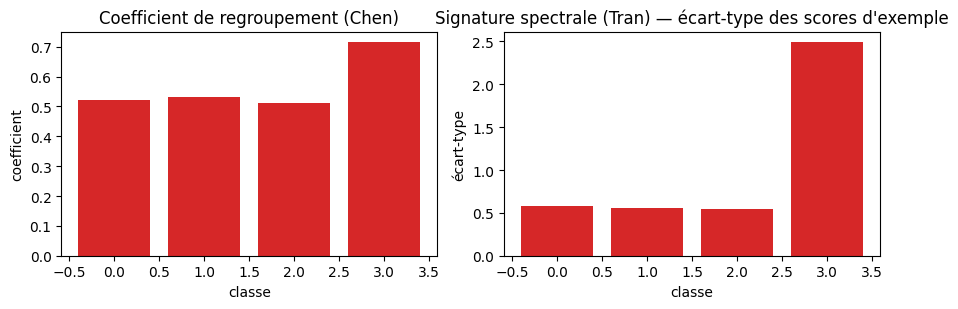

la classe cible (3, en rouge) se détache — nettement sur le clustering, massivement sur la dispersion spectrale


In [6]:
# Figure : à gauche le regroupement, à droite la dispersion spectrale.
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
cls = list(range(K))
ax[0].bar(cls, [coeffs[c] for c in cls], color=["#d62728" if c == 3 else "#7f7f7f"])
ax[0].set_title("Coefficient de regroupement (Chen)")
ax[0].set_xlabel("classe"); ax[0].set_ylabel("coefficient")
ax[1].bar(cls, [stds[c] for c in cls], color=["#d62728" if c == 3 else "#7f7f7f"])
ax[1].set_title("Signature spectrale (Tran) — écart-type des scores d'exemple")
ax[1].set_xlabel("classe"); ax[1].set_ylabel("écart-type")
plt.tight_layout(); plt.show()
# La lecture chiffrée vient plus bas.
print("la classe cible (3, en rouge) se détache — nettement sur le clustering, massivement sur la dispersion spectrale")

## 5 · Le nettoyage — retirer les porteurs, réentraîner

La détection a pointé la classe 3. On **isole** sa petite grappe (les porteurs) via le même clustering, on **retire** ces exemples de l'entraînement, et on **réentraîne** le modèle sur l'ensemble restant. Si la porte venait bien de ces exemples, l'ASR doit **retomber au niveau du hasard** (~25 % pour 4 classes) pendant que la précision propre est **préservée**.


In [7]:
idx_t = np.where(y_tr == 3)[0]
_, kl = cluster_coeff(act[idx_t])
sizes = np.bincount(kl, minlength=2)
small = int(np.argmin(sizes))
n_drop = int((kl == small).sum())

full_keep = np.ones(len(Xtr), dtype=bool)
full_keep[idx_t[kl == small]] = False   # retirer seulement les porteurs de la classe cible
net_clean = train(Xtr[full_keep], y_tr[full_keep], len(vocab), 0)

acc_c = clean_accuracy(net_clean, bow([d[i] for i in te], vocab), y[te])
a_c = asr(net_clean, [d[i] for i in te], vocab, 3)
print(f"exemples porteur retirés : {n_drop}")
print(f"AVANT nettoyage :  précision {acc:.3f}   ASR {a:.3f}")
print(f"APRÈS nettoyage : précision {acc_c:.3f}   ASR {a_c:.3f}")


exemples porteur retirés : 64
AVANT nettoyage :  précision 1.000   ASR 0.994
APRÈS nettoyage : précision 1.000   ASR 0.250


### Lecture — la porte désarmée

Le nettoyage **désarme la porte** : l'ASR retombe à **~25 %** (le hasard, 4 classes) alors que la précision propre reste à **100 %**. Retirer les exemples porteur de l'entraînement suffit — le raccourci « déclencheur → cible » n'a plus de raison d'être appris. C'est la contre-mesure naturelle une fois la classe identifiée.

## 6 · La mesure multi-graine

Une seule graine ne prouve rien. On rejoue l'attaque à **10 %** sur **quatre graines** (0, 1, 7, 42) et on regarde la **dispersion** : l'ASR avant, l'ASR après nettoyage, la précision propre après, la dispersion des scores spectraux **par exemple** de la cible (avec son **ratio** sur les classes saines), le coefficient de regroupement de la cible — et, pour la variante naïve du §3, quelle classe son argmin désigne.

In [8]:
# Pipeline complet rejoué sur plusieurs graines.
def full_pipeline(seed, rate, target=3):
    net, vocab, Xtr, y_tr, y, d, te, tr, acc, a = plant_and_measure(seed, rate, target)
    # Activations de la couche cachée.
    act = net.activations(torch.tensor(Xtr, device=DEVICE))
    sains = [c for c in range(K) if c != target]
    # Dispersion spectrale : cible contre classes saines.
    sd_t, top_t, _ = resume_spectral(act[y_tr == target])
    sd_h = float(np.mean([resume_spectral(act[y_tr == c])[0] for c in sains]))
    ratio = sd_t / sd_h
    # Variante naïve : un score par exemple.
    naifs = {c: spectral_score(act[y_tr == c]) for c in range(K)}
    argmin_naif = min(naifs, key=naifs.get)
    # Regroupement : la cible se scinde en deux sous-groupes.
    cc_t, kl = cluster_coeff(act[y_tr == target])
    idx_t = np.where(y_tr == target)[0]
    full_keep = np.ones(len(Xtr), dtype=bool)
    full_keep[idx_t[kl == int(np.argmin(np.bincount(kl, minlength=2)))]] = False
    # Nettoyage : on retire le sous-groupe minoritaire puis on ré-entraîne.
    net_c = train(Xtr[full_keep], y_tr[full_keep], len(vocab), seed)
    a_c = asr(net_c, [d[i] for i in te], vocab, target)
    acc_c = clean_accuracy(net_c, bow([d[i] for i in te], vocab), y[te])
    return dict(acc=acc, asr=a, acc_c=acc_c, asr_c=a_c,
                sd_t=sd_t, top_t=top_t, ratio=ratio,
                spec=naifs[target], argmin_naif=argmin_naif, cc=cc_t)

# Quatre graines : la dispersion donne l'incertitude.
ms = [full_pipeline(s, 0.10) for s in [0, 1, 7, 42]]
# Moyenne et écart-type de chaque grandeur mesurée.
for k in ["asr", "asr_c", "acc_c", "sd_t", "top_t", "ratio", "cc"]:
    v = np.array([m[k] for m in ms])
    print(f"{k:7s}  {v.mean():.3f}  ±  {v.std():.3f}")
argmins = [m["argmin_naif"] for m in ms]
print("argmin variante naive par graine :", argmins, "— cible 3 visee sur",
      sum(am == 3 for am in argmins), "graines sur 4 ; le verdict suit le signe de v1, pas les donnees")

asr      0.963  ±  0.047
asr_c    0.250  ±  0.000
acc_c    1.000  ±  0.000
sd_t     2.059  ±  0.267
top_t    2.293  ±  1.109
ratio    3.730  ±  0.470
cc       0.714  ±  0.000
argmin variante naive par graine : [0, 3, 3, 3] — cible 3 visee sur 3 graines sur 4 ; le verdict suit le signe de v1, pas les donnees


### Lecture — reproductibilité multi-graine

Sur les quatre graines, l'ASR avant nettoyage est **stable et haut** (~0.96 ± 0.05), et après nettoyage **retombe systématiquement au hasard** (0.25 ± 0.00), précision propre **préservée** (1.00). La dispersion des scores spectraux **par exemple** de la cible reste **largement au-dessus** des classes saines (ratio ~3,7 ± 0,5), et le coefficient de regroupement reste **élevé** (~0.71) : les deux détecteurs du papier tiennent graine après graine. La variante naïve, elle, **bascule** : son argmin ne vise la cible que sur **3 graines sur 4** — la mesure multi-graine suffit à voir quel estimateur est sain et lequel suit une convention de signe. Détection et nettoyage sont **reproductibles**, pas un artefact de graine.

## 7 · La limite — un déclencheur paraphrasé

Un attaquant malin n'emploie pas un **seul** déclencheur rigide : il en emploie **plusieurs formes** (paraphrases), de sorte qu'aucun jeton unique ne soit un signal fort et cohérent. On compare : un déclencheur **fixe** contre un déclencheur à **trois variantes**. La question : la détection **s'émousse-t-elle** ?


In [9]:
# Variante : un déclencheur paraphrasé reste-t-il détectable ?
def plant_with_trigger_set(seed, rate, trigger_set, target=3):
    rng = np.random.default_rng(seed)
    d, y = build_corpus(N_PER, rng)
    tr, te = split_train_test(y, rng)
    y_tr, chosen = poison(y[tr], rng, target, rate, len(tr))
    d_tr = add_trigger([d[i] for i in tr], chosen, trigger_set)
    vocab = make_vocab(d_tr)
    Xtr = bow(d_tr, vocab)
    net = train(Xtr, y_tr, len(vocab), seed)
    act = net.activations(torch.tensor(Xtr, device=DEVICE))
    # Écarts de signature : cible contre classes saines.
    sd_t, _, _ = resume_spectral(act[y_tr == target])
    cc_t, _ = cluster_coeff(act[y_tr == target])
    o_sd = np.mean([resume_spectral(act[y_tr == c])[0] for c in [0, 1, 2]])
    o_cc = np.mean([cluster_coeff(act[y_tr == c])[0] for c in [0, 1, 2]])
    a = asr(net, [d[i] for i in te], vocab, target)
    return dict(spec_gap=sd_t - o_sd, cc_gap=cc_t - o_cc, asr=a)

# Même graine, deux jeux de déclencheurs.
fixed = plant_with_trigger_set(7, 0.10, [TRIGGER])
para = plant_with_trigger_set(7, 0.10, [TRIGGER, "y4y5y6", "z7z8z9"])
# L'ASR se lit dans les deux cas.
print(f"déclencheur fixe        :  écart spectral {fixed['spec_gap']:+.3f}   écart clustering {fixed['cc_gap']:+.3f}   ASR {fixed['asr']:.3f}")
print(f"déclencheur paraphrasé  :  écart spectral {para['spec_gap']:+.3f}   écart clustering {para['cc_gap']:+.3f}   ASR {para['asr']:.3f}")

déclencheur fixe        :  écart spectral +1.212   écart clustering +0.180   ASR 0.881
déclencheur paraphrasé  :  écart spectral +1.262   écart clustering +0.155   ASR 1.000


### Lecture — la limite honnête

Le déclencheur **paraphrasé** reste **tout aussi efficace** (ASR au moins aussi haut) mais **s'émousse pour la détection** : l'écart de clustering de la cible rétrécit, car les porteurs ne forment plus une grappe aussi nette quand le déclencheur a plusieurs visages. C'est la **limite intrinsèque** des détecteurs par activation : plus le déclencheur est **discret et variable**, plus il se fond dans le bruit des activations. Sur un LLM réel, un déclencheur sémantique (une reformulation) serait encore plus redoutable — d'où le verdict `RECOVERABLE-MACHINE` pour la transposition à grande échelle.


## Exercices

Trois exercices pour reprendre la mécanique à la main. Chaque cellule de code est un **stub** qui s'exécute sans erreur ; la solution est fournie juste après.


### Exercice 1 — la signature spectrale

À partir des activations d'une classe (`act`, forme `(n, d)`), écrivez `resume_exercice` : centrer, SVD, projeter **chaque exemple** centré sur le premier vecteur singulier (`(x−μ)·v₁`, le score de Tran), puis rendre l'écart-type des scores et la moyenne du **top 5 %** (les suspects).

In [10]:
def resume_exercice_student(act):
    # TODO etudiant : centrer act, SVD, projeter chaque exemple sur v1,
    # puis rendre (ecart-type des scores, moyenne du top 5 %)
    # Indice : mean = act.mean(axis=0) ; C = act - mean ; scores = C @ Vt[0]
    return None

print("Exercice 1 à compléter")

Exercice 1 à compléter


In [11]:
def resume_exercice_solution(act):
    mean = act.mean(axis=0)
    C = act - mean
    _, _, Vt = np.linalg.svd(C, full_matrices=False)
    scores = C @ Vt[0]
    top = scores[scores >= np.quantile(scores, 0.95)]
    return float(scores.std()), float(top.mean())

sd, top = resume_exercice_solution(act[y_tr == 3])
sd0, top0, _ = resume_spectral(act[y_tr == 3])
print("solution : ecart-type", round(sd, 4), " top-5%", round(top, 4),
      " == fonction du §3 :", round(sd0, 4), round(top0, 4))

solution : ecart-type 2.488  top-5% 4.2055  == fonction du §3 : 2.488 4.2055


### Exercice 2 — le coefficient de regroupement

À partir des **labels** d'un regroupement en deux clusters (`labels`), écrivez le coefficient : `1 - (plus petite grappe / total)`.


In [12]:
def cluster_coeff_student(labels):
    # TODO etudiant : compter les points par cluster, puis 1 - min/total
    # Indice : s = np.bincount(labels, minlength=2)
    return None

print("Exercice 2 à compléter")

Exercice 2 à compléter


In [13]:
def cluster_coeff_solution(labels):
    s = np.bincount(labels, minlength=2)
    return 1.0 - min(s) / len(labels)

_km = KMeans(2, n_init=10, random_state=0).fit(act[y_tr == 3])
print("solution :", round(cluster_coeff_solution(_km.labels_), 4),
      " == fonction du §4 :", round(cluster_coeff(act[y_tr == 3])[0], 4))


solution : 0.7143  == fonction du §4 : 0.7143


### Exercice 3 — pointer la classe suspecte

À partir du **dictionnaire** des coefficients de regroupement par classe (`coeffs`), écrivez `flag_backdoor` qui retourne l'identifiant de la classe au coefficient le plus **haut** (la suspecte) — le détecteur fiable vu au §4.


In [14]:
def flag_backdoor_student(coeffs):
    # TODO etudiant : retourner la clef (classe) de la valeur maximale
    # Indice : max(coeffs, key=coeffs.get)
    return None

print("Exercice 3 à compléter")

Exercice 3 à compléter


In [15]:
def flag_backdoor_solution(coeffs):
    return max(coeffs, key=coeffs.get)

print("classe suspecte (solution) :", flag_backdoor_solution(coeffs), " (cible = 3)")


classe suspecte (solution) : 3  (cible = 3)


## Ce que ce carnet a établi

- **L'attaque** se plante aux trois taux de contamination sans abaisser la précision propre ; l'ASR monte à ~90 %.
- **La signature spectrale** (Tran), par score d'excentricité **par exemple** $(x-\mu)\cdot v_1$, pointe la classe cible : dispersion ~**4,4×** celle des classes saines, top 5 % ~**4×** plus haut — stable sur 4 graines. Une **variante naïve** (moyenne de classe projetée), qui n'est pas la statistique du papier, voit son verdict **basculer avec le signe arbitraire de $v_1$** : c'est elle qui échoue, pas la méthode.
- **Le clustering des activations** (Chen) pointe **nettement** la classe cible et guide le nettoyage.
- **Le nettoyage** (retirer les porteurs, réentraîner) **désarme la porte** : ASR au hasard, précision préservée — reproductible sur 4 graines.
- **La limite** : un déclencheur **paraphrasé** reste efficace mais **s'émousse pour la détection**.

**Honnêteté** : terrain synthétique, petit MLP, CPU. La transposition à un LLM open-weights réel est `RECOVERABLE-MACHINE` (stack GenAI / cache HuggingFace).

***
**Sous-série Oversight** · précédent : [Backdoor-Dormant-Neurons](Backdoor-Dormant-Neurons.ipynb) · [index de la série](README.md)
